In [ ]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Base classifiers
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression

# Ensemble algorithms
from sklearn.ensemble import (
    StackingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/spambase/spambase.data"
)

data = pd.read_csv(url, header=None)

# Separate features and target
X = data.iloc[:, :-1]
y = data.iloc[:, -1].astype(int)

# Rename feature columns
X.columns = [f"feature_{i}" for i in range(1, 58)]

print("DATASET INFORMATION")
print("-------------------")

print("Total records:", X.shape[0])
print("Total features:", X.shape[1])

print("\nFirst five records:")
display(X.head())

print("\nClass distribution:")
print(y.value_counts().rename(index={
    0: "Non-Spam",
    1: "Spam"
}))

print("\nMissing values:", X.isnull().sum().sum())

DATASET INFORMATION
-------------------
Total records: 4601
Total features: 57

First five records:


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,...,feature_48,feature_49,feature_50,feature_51,feature_52,feature_53,feature_54,feature_55,feature_56,feature_57
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.0,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.0,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.0,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.0,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.0,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191



Class distribution:
57
Non-Spam    2788
Spam        1813
Name: count, dtype: int64

Missing values: 0


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("TRAIN-TEST SPLIT")
print("----------------")

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

TRAIN-TEST SPLIT
----------------
Training samples: 3680
Testing samples: 921
Training shape: (3680, 57)
Testing shape: (921, 57)


In [ ]:
base_models = {
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    "Naive Bayes": GaussianNB()
}

print("Base classifiers defined successfully!")

Base classifiers defined successfully!


In [ ]:
stacking_estimators = [
    ("svm", base_models["SVM"]),
    ("decision_tree", base_models["Decision Tree"]),
    ("knn", base_models["KNN"]),
    ("naive_bayes", base_models["Naive Bayes"])
]

stacking_model = StackingClassifier(
    estimators=stacking_estimators,

    # Meta-classifier
    final_estimator=LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    cv=5,
    stack_method="predict_proba",
    n_jobs=-1
)

print("Stacking Ensemble defined successfully!")

Stacking Ensemble defined successfully!


In [ ]:
start_time = time.time()

stacking_model.fit(X_train, y_train)

stacking_time = time.time() - start_time

print("Stacking Ensemble trained successfully!")
print("Execution Time:", stacking_time, "seconds")

Stacking Ensemble trained successfully!
Execution Time: 17.188968181610107 seconds


In [ ]:
weak_learner = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

adaboost_model = AdaBoostClassifier(
    estimator=weak_learner,
    n_estimators=100,
    learning_rate=1.0,
    random_state=42
)

print("AdaBoost Ensemble defined successfully!")

AdaBoost Ensemble defined successfully!


In [ ]:
start_time = time.time()

adaboost_model.fit(X_train, y_train)

adaboost_time = time.time() - start_time

print("AdaBoost trained successfully!")
print("Execution Time:", adaboost_time, "seconds")

AdaBoost trained successfully!
Execution Time: 0.9347326755523682 seconds


In [ ]:
voting_estimators = [
    ("svm", base_models["SVM"]),
    ("decision_tree", base_models["Decision Tree"]),
    ("knn", base_models["KNN"]),
    ("naive_bayes", base_models["Naive Bayes"])
]

voting_model = VotingClassifier(
    estimators=voting_estimators,
    voting="hard",
    n_jobs=-1
)

print("Voting Ensemble defined successfully!")

Voting Ensemble defined successfully!


In [ ]:
start_time = time.time()

voting_model.fit(X_train, y_train)

voting_time = time.time() - start_time

print("Voting Ensemble trained successfully!")
print("Execution Time:", voting_time, "seconds")

Voting Ensemble trained successfully!
Execution Time: 2.2725164890289307 seconds


In [ ]:
all_models = {
    # Base classifiers
    "SVM": base_models["SVM"],
    "Decision Tree": base_models["Decision Tree"],
    "KNN": base_models["KNN"],
    "Naive Bayes": base_models["Naive Bayes"],

    # Ensemble classifiers
    "Stacking": stacking_model,
    "AdaBoost": adaboost_model,
    "Voting": voting_model
}

print("Total models:", len(all_models))

Total models: 7


In [ ]:
results = []
predictions = {}
trained_models = {}

for name, model in all_models.items():

    print("\nTraining:", name)

    start_time = time.time()

    model.fit(X_train, y_train)

    training_time = time.time() - start_time

    # Predictions
    y_pred = model.predict(X_test)

    predictions[name] = y_pred
    trained_models[name] = model

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    # Log loss requires probability estimates
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)
        loss = log_loss(y_test, y_prob, labels=[0, 1])
    else:
        loss = np.nan

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Log Loss": loss,
        "Training Time": training_time
    })

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-Score:", round(f1, 4))
    print("Log Loss:", round(loss, 4) if not np.isnan(loss) else "N/A")
    print("Training Time:", round(training_time, 4), "seconds")

print("\nAll models evaluated successfully!")


Training: SVM
Accuracy: 0.9273
Precision: 0.9277
Recall: 0.8843
F1-Score: 0.9055
Log Loss: 0.231
Training Time: 8.236 seconds

Training: Decision Tree
Accuracy: 0.9088
Precision: 0.8974
Recall: 0.8678
F1-Score: 0.8824
Log Loss: 1.3062
Training Time: 0.1862 seconds

Training: KNN
Accuracy: 0.9077
Precision: 0.8861
Recall: 0.8788
F1-Score: 0.8824
Log Loss: 0.9458
Training Time: 0.0334 seconds

Training: Naive Bayes
Accuracy: 0.8339
Precision: 0.7178
Recall: 0.9532
F1-Score: 0.8189
Log Loss: 4.2251
Training Time: 0.0084 seconds

Training: Stacking
Accuracy: 0.9349
Precision: 0.922
Recall: 0.9118
F1-Score: 0.9169
Log Loss: 0.1785
Training Time: 13.8645 seconds

Training: AdaBoost
Accuracy: 0.9273
Precision: 0.9253
Recall: 0.8871
F1-Score: 0.9058
Log Loss: 0.5274
Training Time: 0.8763 seconds

Training: Voting
Accuracy: 0.9338
Precision: 0.9364
Recall: 0.8926
F1-Score: 0.914
Log Loss: N/A
Training Time: 1.9417 seconds

All models evaluated successfully!


In [ ]:
results_df = pd.DataFrame(results)

results_df = results_df.set_index("Model")

print("FINAL PERFORMANCE COMPARISON")
display(results_df.round(4))

FINAL PERFORMANCE COMPARISON


,Accuracy,Precision,Recall,F1-Score,Log Loss,Training Time
Model,,,,,,
SVM,0.9273,0.9277,0.8843,0.9055,0.2310,8.2360
Decision Tree,0.9088,0.8974,0.8678,0.8824,1.3062,0.1862
KNN,0.9077,0.8861,0.8788,0.8824,0.9458,0.0334
Naive Bayes,0.8339,0.7178,0.9532,0.8189,4.2251,0.0084
Stacking,0.9349,0.9220,0.9118,0.9169,0.1785,13.8645
AdaBoost,0.9273,0.9253,0.8871,0.9058,0.5274,0.8763
Voting,0.9338,0.9364,0.8926,0.9140,NaN,1.9417


In [ ]:
print("BEST MODEL BY PERFORMANCE METRIC")
print("--------------------------------")

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

for metric in metrics:

    best_model = results_df[metric].idxmax()

    best_value = results_df[metric].max()

    print(
        f"Highest {metric}: {best_model} "
        f"({best_value:.4f})"
    )

best_loss = results_df["Log Loss"].idxmin()

print(
    "\nLowest Log Loss:",
    best_loss,
    f"({results_df.loc[best_loss, 'Log Loss']:.4f})"
)

print("\nFastest Training Model:")
print(results_df["Training Time"].idxmin())

BEST MODEL BY PERFORMANCE METRIC
--------------------------------
Highest Accuracy: Stacking (0.9349)
Highest Precision: Voting (0.9364)
Highest Recall: Naive Bayes (0.9532)
Highest F1-Score: Stacking (0.9169)

Lowest Log Loss: Stacking (0.1785)

Fastest Training Model:
Naive Bayes


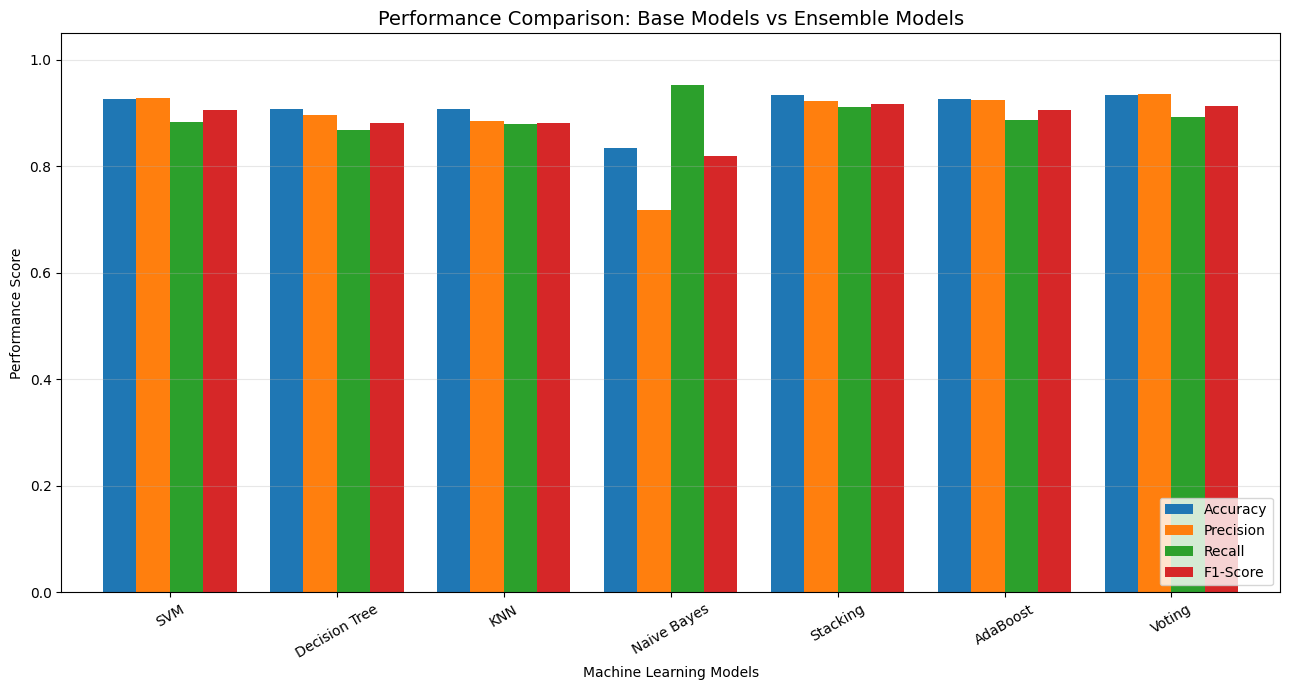

In [ ]:
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

results_df[metrics_to_plot].plot(
    kind="bar",
    figsize=(13, 7),
    ylim=(0, 1.05),
    width=0.8
)

plt.title(
    "Performance Comparison: Base Models vs Ensemble Models",
    fontsize=14
)

plt.xlabel("Machine Learning Models")
plt.ylabel("Performance Score")

plt.xticks(rotation=30)

plt.legend(loc="lower right")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()

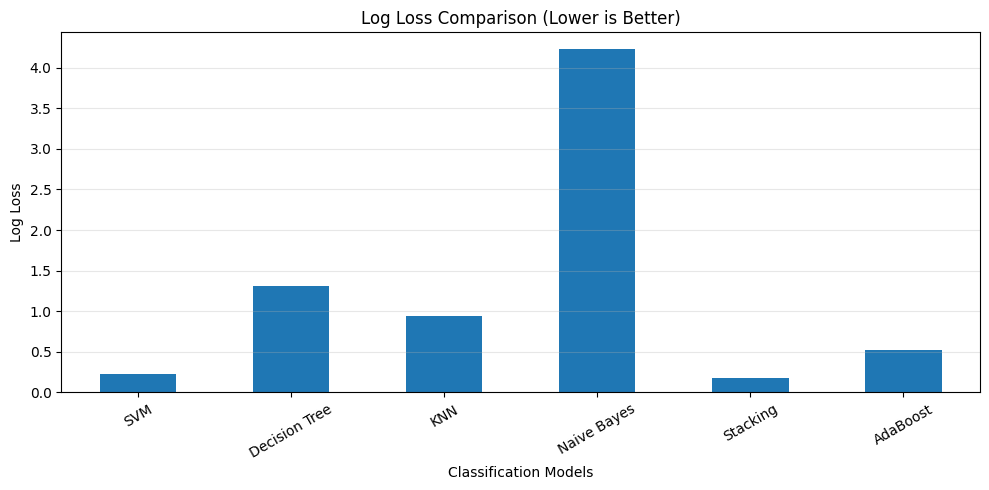

In [ ]:
results_df["Log Loss"].dropna().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Log Loss Comparison (Lower is Better)")

plt.xlabel("Classification Models")
plt.ylabel("Log Loss")

plt.xticks(rotation=30)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()

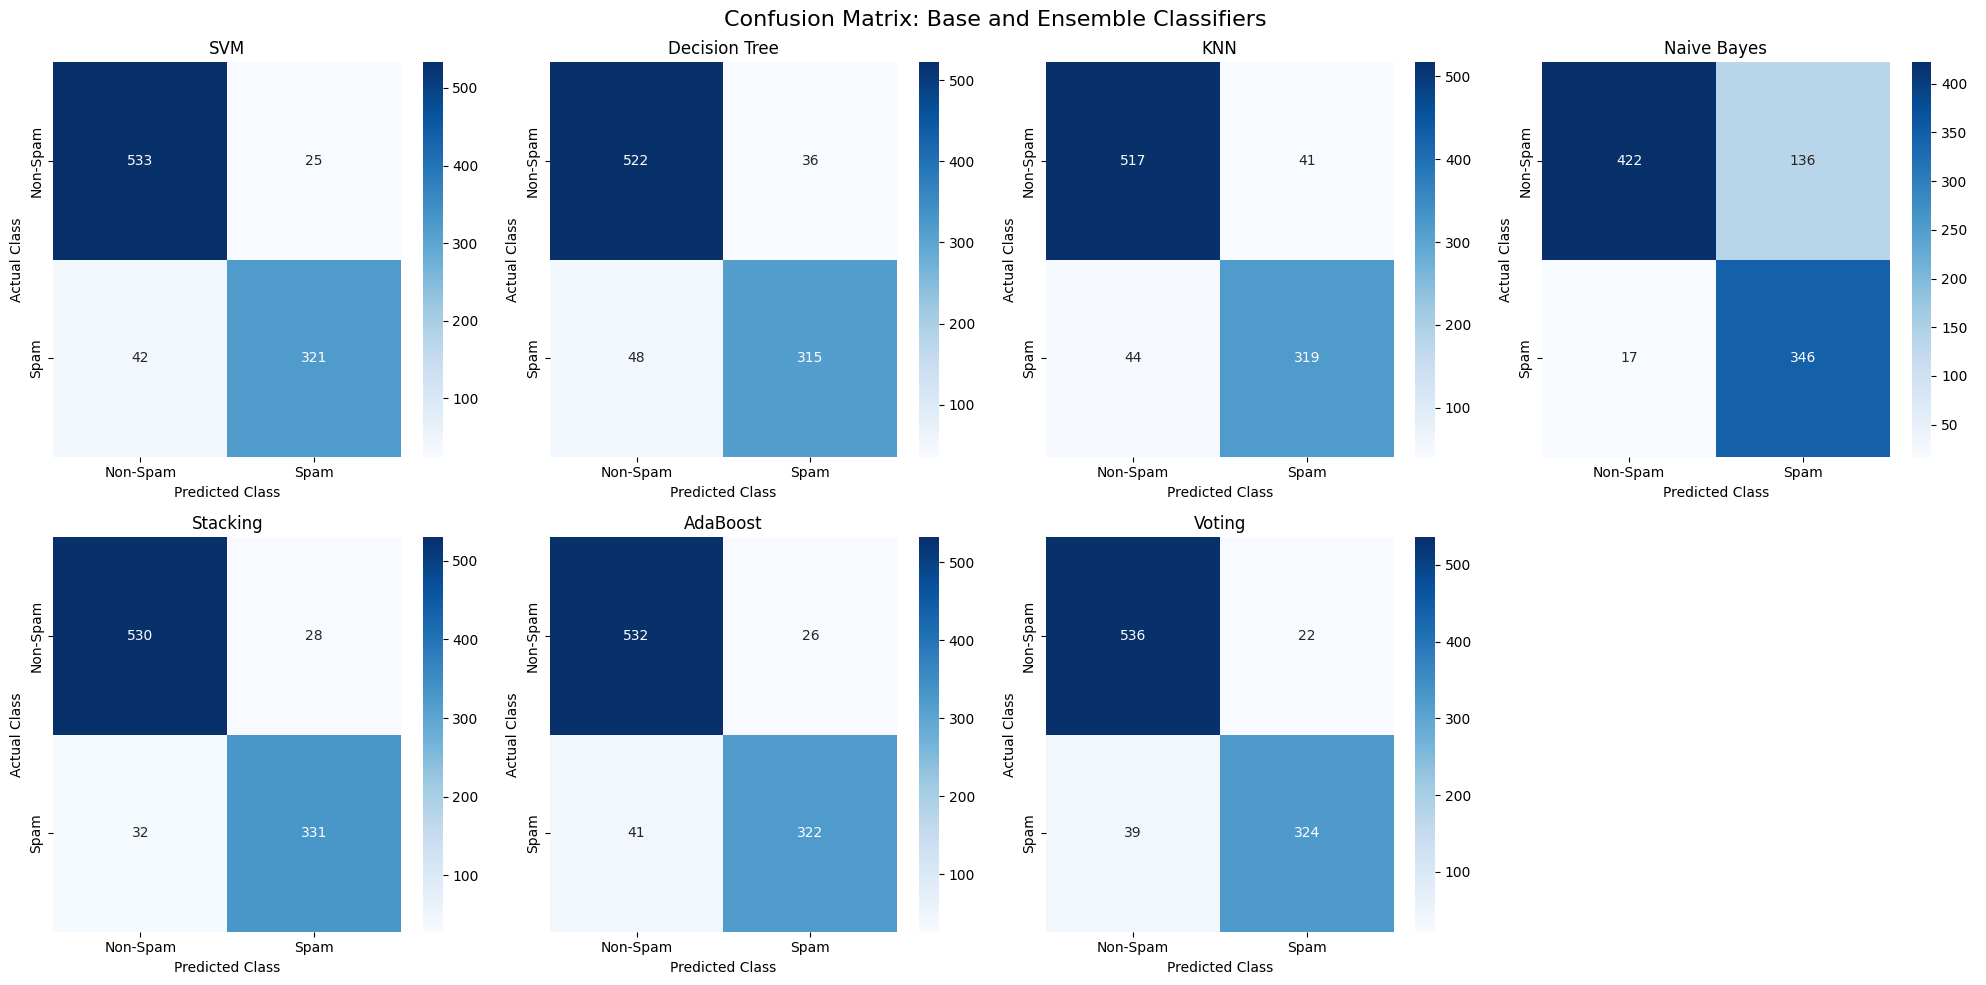

In [ ]:
fig, axes = plt.subplots(
    2, 4,
    figsize=(20, 10)
)

for ax, (name, y_pred) in zip(
    axes.flatten(),
    predictions.items()
):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Non-Spam", "Spam"],
        yticklabels=["Non-Spam", "Spam"],
        ax=ax
    )

    ax.set_title(name)

    ax.set_xlabel("Predicted Class")

    ax.set_ylabel("Actual Class")

# Hide unused eighth subplot
axes.flatten()[-1].axis("off")

plt.suptitle(
    "Confusion Matrix: Base and Ensemble Classifiers",
    fontsize=16
)

plt.tight_layout()

plt.show()


In [ ]:
for name, y_pred in predictions.items():

    print("\n" + "=" * 60)

    print("CLASSIFICATION REPORT:", name)

    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Non-Spam", "Spam"],
            zero_division=0
        )
    )


CLASSIFICATION REPORT: SVM
              precision    recall  f1-score   support

    Non-Spam       0.93      0.96      0.94       558
        Spam       0.93      0.88      0.91       363

    accuracy                           0.93       921
   macro avg       0.93      0.92      0.92       921
weighted avg       0.93      0.93      0.93       921


CLASSIFICATION REPORT: Decision Tree
              precision    recall  f1-score   support

    Non-Spam       0.92      0.94      0.93       558
        Spam       0.90      0.87      0.88       363

    accuracy                           0.91       921
   macro avg       0.91      0.90      0.90       921
weighted avg       0.91      0.91      0.91       921


CLASSIFICATION REPORT: KNN
              precision    recall  f1-score   support

    Non-Spam       0.92      0.93      0.92       558
        Spam       0.89      0.88      0.88       363

    accuracy                           0.91       921
   macro avg       0.90      0.90 

In [ ]:
import os

os.makedirs("outputs", exist_ok=True)

# Save comparison table
results_df.to_csv(
    "outputs/ensemble_performance_comparison.csv"
)

# Save performance graph
ax = results_df[metrics_to_plot].plot(
    kind="bar",
    figsize=(13, 7),
    ylim=(0, 1.05)
)

plt.title("Base Models vs Ensemble Models")
plt.xlabel("Models")
plt.ylabel("Scores")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    "outputs/performance_comparison.png",
    dpi=300
)

plt.close()

# Save log loss graph
results_df["Log Loss"].dropna().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Log Loss Comparison")
plt.ylabel("Log Loss")
plt.tight_layout()

plt.savefig(
    "outputs/log_loss_comparison.png",
    dpi=300
)

plt.close()

print("All results saved successfully!")

All results saved successfully!
